# Identificação de espécies de morcegos com uma rede MLP

**PSI0325 — Fundamentos de Adaptação e Aprendizado de Máquina (Poli-USP) · Trabalho final**
Victor Emanuel Ramos de Carvalho

Dado o vetor de medidas acústicas de uma gravação de ecolocalização, a rede
prevê qual das 8 espécies a emitiu. Este notebook reúne, em ordem, as três
partes pedidas: **(i)** preparação do ambiente e dos dados, **(ii)** treinamento
e **(iii)** avaliação do modelo treinado.

As escolhas de modelo e de hiperparâmetros foram feitas antes, olhando só a
validação, nos notebooks de trabalho do repositório (`03` a `08`); aqui fica a
configuração final, e o artigo traz as justificativas. O conjunto de teste é
usado uma única vez, no fim.

## Dados

> **[PREENCHER — aguardando orientação do professor]**
>
> A base é pesquisa **não publicada** (projetos Cidade Viva, em Montes Claros, e
> levantamento do Parque Estadual da Lapa Grande, MG; detectores SM2BAT a 768 kHz,
> 2024–2026; identificação por especialistas). Referência: **[referência a obter com o
> responsável pelos dados]**.
>
> Como obter os arquivos para rodar este notebook: **[descrever aqui — por exemplo,
> arquivos enviados junto com a entrega, ou disponíveis mediante autorização de ...]**.
>
> Arquivos esperados (exportação em CSV das abas da planilha original), na pasta
> indicada em `PASTA_DADOS` abaixo:
> - `... - Cidade Viva - Identificação.csv`
> - `... - PELG - Identificação.csv`

Sem os arquivos, o notebook pode ser lido com as saídas já executadas.

---
# (i) Preparação do ambiente e dos dados

Bibliotecas: PyTorch para a rede; NumPy para divisão, normalização e métricas
(implementadas a partir das fórmulas dos slides, sem scikit-learn); pandas só
para ler os CSVs; matplotlib para as figuras. Sementes fixas para que o
resultado seja reproduzível.

In [1]:
import copy
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

np.random.seed(42)
torch.manual_seed(42)

PASTA_DADOS = "../banco/"  # [PREENCHER se os dados forem entregues em outro lugar]
ARQUIVO = PASTA_DADOS + "Cidade Viva e PELG Bioacústica (OFICIAL).xlsx - {}.csv"

print("Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__)
print("Treino em CPU")

Python 3.13.13 | torch 2.14.0+cpu | numpy 2.5.3 | pandas 3.0.6
Treino em CPU


## Leitura e junção

Cada linha da aba *Identificação* é uma gravação, com a espécie identificada e as
medidas médias do pulso. As duas abas (um projeto cada) têm as mesmas colunas e
são empilhadas. O nome do arquivo é padronizado (sem a anotação entre
parênteses e sem o sufixo `_000`) para identificar gravações repetidas.

In [2]:
identificacao = pd.concat([pd.read_csv(ARQUIVO.format("Cidade Viva - Identificação")),
                           pd.read_csv(ARQUIVO.format("PELG - Identificação"))], ignore_index=True)


def normaliza_arquivo(nome):
    if pd.isna(nome):
        return nome
    nome = nome.strip()
    nome = nome.split("(")[0].strip()
    return re.sub(r"_000$", "", nome)


identificacao["Arquivo_norm"] = identificacao["Arquivo"].apply(normaliza_arquivo)
print("Gravações:", len(identificacao), "| espécies/sonótipos:", identificacao["Espécie/Sonótipo"].nunique())

Gravações: 14540 | espécies/sonótipos: 23


## Recorte e limpeza

- **8 espécies** com pelo menos 379 gravações. O sonótipo `Molossidae1` (identificação
  só até família) fica de fora.
- **5 gravações com erro grave**: *Myotis lavali* com FME abaixo de 10 kHz e
  *Eumops* sp. com FME acima de 45 kHz, muito fora da faixa da espécie.
- **Duplicatas exatas** (mesma gravação, mesma espécie): fica uma cópia. Gravações
  com duas espécies têm uma linha por espécie e são mantidas.

In [3]:
contagem = identificacao["Espécie/Sonótipo"].value_counts().drop("Molossidae1")
especies_recorte = contagem[contagem >= 379].index.tolist()
dados = identificacao[identificacao["Espécie/Sonótipo"].isin(especies_recorte)].copy()

COL_FMIN, COL_FMAX, COL_FME, COL_DUR = "Fmin (kHz)", "Fmax (kHz)", "FME (kHz)", "Duração (ms)"
erro_lavali = (dados["Espécie/Sonótipo"] == "Myotis_lavali") & (dados[COL_FME] < 10)
erro_eumops = (dados["Espécie/Sonótipo"] == "Eumops_sp") & (dados[COL_FME] > 45)
dados = dados[~(erro_lavali | erro_eumops)]
antes = len(dados)
dados = dados.drop_duplicates(subset=["Arquivo_norm", "Espécie/Sonótipo"], keep="first")

print("Erros graves removidos:", int((erro_lavali | erro_eumops).sum()), "| duplicatas removidas:", antes - len(dados))
print("Gravações após a limpeza:", len(dados))
print(dados["Espécie/Sonótipo"].value_counts().to_string())

Erros graves removidos: 5 | duplicatas removidas: 27
Gravações após a limpeza: 13408
Espécie/Sonótipo
Myotis_lavali             7284
Molossus_molossus         1648
Lasiurus_blossevillii     1082
Neoeptesicus_furinalis    1014
Eumops_sp                  723
Molossus_currentium        716
Molossops_temminckii       557
Myotis_nigricans           384


## Entradas da rede

Cinco medidas por gravação: **Fmin, Fmax, largura de banda, FME** (frequência de
maior energia) e **duração**. A largura de banda é recalculada como Fmax − Fmin,
porque a coluna original tem cerca de 8,5% de valores corrompidos.

Colunas **não usadas**, e por quê:
- `Tipo_pulso`, `Família`, `Gênero`, `Subfamília`: na planilha são fórmulas do
  Excel calculadas a partir do nome da espécie. Usá-las seria dar a resposta como
  entrada (vazamento de rótulo).
- `Fstart(s)`, `Fend(s)`: pelo cabeçalho, são o instante do pulso na gravação, em
  segundos, não uma medida do chamado.
- Local, data, gravador: dizem onde e quando foi gravado, não como é o pulso.

In [4]:
X_bruto = np.column_stack([
    dados[COL_FMIN].to_numpy(),
    dados[COL_FMAX].to_numpy(),
    (dados[COL_FMAX] - dados[COL_FMIN]).to_numpy(),  # largura de banda recalculada
    dados[COL_FME].to_numpy(),
    dados[COL_DUR].to_numpy(),
])
ATRIBUTOS = ["Fmin", "Fmax", "Largura de banda", "FME", "Duração"]
especie = dados["Espécie/Sonótipo"].to_numpy()

ESPECIES = pd.Series(especie).value_counts().index.tolist()  # da mais para a menos frequente
y = np.array([ESPECIES.index(e) for e in especie])
N_CLASSES = len(ESPECIES)
print("X:", X_bruto.shape, "| algum valor faltando?", np.isnan(X_bruto).any())

X: (13408, 5) | algum valor faltando? False


## Divisão em treino, validação e teste

70% / 15% / 15%, **estratificada por espécie** (cada espécie aparece na mesma
proporção nos três conjuntos), com semente 42. O treino ajusta os pesos; a
validação escolhe a época e os hiperparâmetros; o teste só é usado na avaliação
final.

In [5]:
def divisao_estratificada(rotulos, indices, proporcoes=(0.70, 0.15, 0.15), semente=42):
    rng = np.random.default_rng(semente)
    treino, val, teste = [], [], []
    for classe in np.unique(rotulos):
        idx = rng.permutation(indices[rotulos == classe])
        n_tr, n_va = int(round(len(idx) * proporcoes[0])), int(round(len(idx) * proporcoes[1]))
        treino.append(idx[:n_tr])
        val.append(idx[n_tr:n_tr + n_va])
        teste.append(idx[n_tr + n_va:])  # o resto vai para o teste
    return np.concatenate(treino), np.concatenate(val), np.concatenate(teste)


idx_tr, idx_va, idx_te = divisao_estratificada(especie, dados.index.to_numpy())
pos_tr, pos_va, pos_te = (dados.index.get_indexer(i) for i in (idx_tr, idx_va, idx_te))

tabela = pd.DataFrame({nome: pd.Series(especie[p]).value_counts()
                       for nome, p in [("treino", pos_tr), ("validação", pos_va), ("teste", pos_te)]}).loc[ESPECIES]
tabela.loc["total"] = tabela.sum()
tabela

,treino,validação,teste
Myotis_lavali,5099,1093,1092
Molossus_molossus,1154,247,247
Lasiurus_blossevillii,757,162,163
Neoeptesicus_furinalis,710,152,152
Eumops_sp,506,108,109
Molossus_currentium,501,107,108
Molossops_temminckii,390,84,83
Myotis_nigricans,269,58,57
total,9386,2011,2011


## Normalização

Média zero e variância unitária em cada atributo (Slides_5), com média e desvio
calculados **só no treino** e aplicados aos três conjuntos. Sem isso, atributos
em escalas diferentes (kHz e ms) pesariam de forma desigual no gradiente.

In [6]:
media, desvio = X_bruto[pos_tr].mean(axis=0), X_bruto[pos_tr].std(axis=0)
X = ((X_bruto - media) / desvio).astype(np.float32)

Xtr, ytr = X[pos_tr], y[pos_tr]
Xva, yva = X[pos_va], y[pos_va]
Xte, yte = X[pos_te], y[pos_te]
print("Média no treino após normalizar:", Xtr.mean(axis=0).round(3))
print("Desvio no treino após normalizar:", Xtr.std(axis=0).round(3))

Média no treino após normalizar: [-0. -0.  0. -0. -0.]
Desvio no treino após normalizar: [1. 1. 1. 1. 1.]


---
# (ii) Treinamento

**Modelo:** MLP com uma camada oculta de 8 neurônios e ativação tangente
hiperbólica, e 8 neurônios de saída (um por espécie). A saída passa pela
*softmax* (Slides_5), que dá a probabilidade de cada espécie; a espécie prevista é
a de maior probabilidade.

**Função custo:** entropia cruzada categórica (Slides_5). O `CrossEntropyLoss` do
PyTorch já aplica a softmax internamente, então a rede termina numa camada
linear. Como as classes são desbalanceadas (19:1), cada exemplo pesa o inverso
da frequência da sua espécie, `n / (N_classes · n_espécie)`, calculado no treino:
errar uma espécie rara custa mais.

**Otimização:** Adam com passo 0,01, mini-batch de 64, até 1000 épocas. A cada
época mede-se a perda na validação e guardam-se os pesos da época de menor
perda de validação (evita o sobreajuste).

Esta configuração foi escolhida entre 22 testadas (neurônios, camadas, ativação,
inicialização, otimizador, passo, dropout, ℓ2, mini-batch): todas ficaram entre
0,951 e 0,968 de acurácia balanceada na validação, e esta é a mais simples dentro
da variação entre sementes (notebook `07`).

In [7]:
class MLP(nn.Module):
    def __init__(self, n_entradas=5, n_ocultos=8, n_classes=N_CLASSES):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(n_entradas, n_ocultos),
            nn.Tanh(),
            nn.Linear(n_ocultos, n_classes),  # softmax fica dentro do CrossEntropyLoss
        )

    def forward(self, x):
        return self.rede(x)


PESOS = len(ytr) / (N_CLASSES * np.bincount(ytr, minlength=N_CLASSES))
print("Peso de cada espécie na função custo:")
for e, p in zip(ESPECIES, PESOS):
    print(f"  {e:24s} {p:.2f}")

Peso de cada espécie na função custo:
  Myotis_lavali            0.23
  Molossus_molossus        1.02
  Lasiurus_blossevillii    1.55
  Neoeptesicus_furinalis   1.65
  Eumops_sp                2.32
  Molossus_currentium      2.34
  Molossops_temminckii     3.01
  Myotis_nigricans         4.36


In [8]:
def treina(modelo, otimizador, n_epocas, semente):
    torch.manual_seed(semente)
    criterio = nn.CrossEntropyLoss(weight=torch.tensor(PESOS, dtype=torch.float32))
    loader = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)), batch_size=64, shuffle=True)
    tXva, tyva = torch.from_numpy(Xva), torch.from_numpy(yva)
    perdas_treino, perdas_val = [], []
    melhor, melhores_pesos, melhor_epoca = float("inf"), None, -1
    for epoca in range(n_epocas):
        modelo.train()
        acumulada = 0.0
        for xb, yb in loader:
            otimizador.zero_grad()
            perda = criterio(modelo(xb), yb)
            perda.backward()
            otimizador.step()
            acumulada += perda.item() * len(xb)
        perdas_treino.append(acumulada / len(ytr))

        modelo.eval()
        with torch.no_grad():
            perdas_val.append(criterio(modelo(tXva), tyva).item())
        if perdas_val[-1] < melhor:
            melhor, melhores_pesos, melhor_epoca = perdas_val[-1], copy.deepcopy(modelo.state_dict()), epoca + 1
    modelo.load_state_dict(melhores_pesos)
    return melhor_epoca, perdas_treino, perdas_val

Três treinos com sementes diferentes (inicialização dos pesos e ordem dos
mini-batches), para medir quanto o resultado depende do sorteio.

In [9]:
SEMENTES = [0, 1, 2]
modelos, curvas = [], []
for s in SEMENTES:
    torch.manual_seed(s)
    modelo = MLP()
    epoca, p_tr, p_va = treina(modelo, torch.optim.Adam(modelo.parameters(), lr=0.01), 1000, s)
    modelos.append(modelo)
    curvas.append((epoca, p_tr, p_va))
    print(f"semente {s}: pesos da época {epoca} (perda de validação {min(p_va):.3f})")

semente 0: pesos da época 818 (perda de validação 0.140)


semente 1: pesos da época 339 (perda de validação 0.156)


semente 2: pesos da época 438 (perda de validação 0.146)


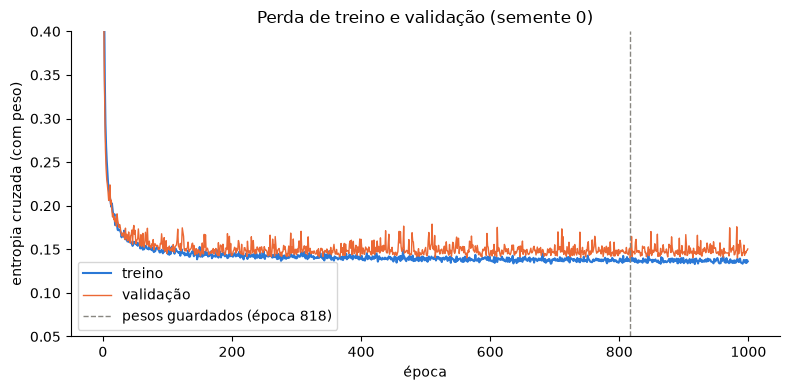

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
epoca, p_tr, p_va = curvas[0]
ax.plot(p_tr, label="treino", color="#2a78d6")
ax.plot(p_va, label="validação", color="#eb6834", linewidth=1)
ax.axvline(epoca - 1, color="#898781", linestyle="--", linewidth=1, label=f"pesos guardados (época {epoca})")
ax.set_xlabel("época")
ax.set_ylabel("entropia cruzada (com peso)")
ax.set_ylim(0.05, 0.4)
ax.set_title("Perda de treino e validação (semente 0)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

As duas curvas andam juntas: com 8 neurônios não há sobreajuste visível. Com
redes maiores (64 neurônios), a perda de treino continua caindo enquanto a de
validação sobe (notebook `07`); guardar os pesos do mínimo da validação protege
contra isso.

---
# (iii) Avaliação do modelo treinado

## Métricas

Implementadas a partir da **matriz de confusão** (Slides_6), com linha = espécie
prevista e coluna = espécie verdadeira. Para cada espécie, tratando-a como positiva:
**sensibilidade** (das gravações dela, quantas o modelo acha) e **precisão**
(quando o modelo diz que é ela, quantas vezes acerta).

- **Acurácia balanceada** (métrica principal): média das sensibilidades das 8
  espécies. Cada espécie pesa igual; com 19:1, a acurácia comum seria dominada por
  *Myotis lavali*.
- **F1 macro**: média do F1 de cada espécie (Grandini et al., 2020).
- **Acurácia**: fração de acertos, para referência.

In [11]:
def prever(modelo, Xp):
    modelo.eval()
    with torch.no_grad():
        return torch.softmax(modelo(torch.from_numpy(Xp)), dim=1).numpy().argmax(axis=1)


def matriz_confusao(y_real, y_prev):
    m = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
    for p, r in zip(y_prev, y_real):
        m[p, r] += 1  # linha = previsto, coluna = verdadeiro
    return m


def metricas(m):
    vp = np.diag(m).astype(float)
    sens = vp / m.sum(axis=0)
    total_previsto = m.sum(axis=1)
    prec = np.divide(vp, total_previsto, out=np.zeros_like(vp), where=total_previsto > 0)
    f1 = np.divide(2 * prec * sens, prec + sens, out=np.zeros_like(vp), where=(prec + sens) > 0)
    return {"acurácia balanceada": sens.mean(), "F1 macro": f1.mean(), "acurácia": vp.sum() / m.sum(),
            "sens": sens, "prec": prec}

## Referências para comparar

- **Modelo linear**: regressão softmax (uma camada `Linear(5, 8)`, sem camada
  oculta), com a **mesma** função custo com peso, SGD com passo 0,1 e 2000 épocas.
  A única diferença para a MLP é a camada oculta.
- **Regra de FME da chave de identificação**: sem aprendizado; cada gravação recebe
  a espécie cuja FME típica, segundo a chave dos especialistas, está mais perto da
  FME medida. Faixas da chave convertidas em números pelo ponto médio.

In [12]:
lineares = []
for s in SEMENTES:
    torch.manual_seed(s)
    linear = nn.Sequential(nn.Linear(5, N_CLASSES))
    treina(linear, torch.optim.SGD(linear.parameters(), lr=0.1), 2000, s)
    lineares.append(linear)

FME_CHAVE = {"Eumops_sp": 18.0, "Molossus_currentium": 30.0, "Molossus_molossus": 34.0,
             "Neoeptesicus_furinalis": 39.0, "Lasiurus_blossevillii": 46.0,
             "Molossops_temminckii": 50.0, "Myotis_lavali": 50.5, "Myotis_nigricans": 53.5}
centros = np.array([FME_CHAVE[e] for e in ESPECIES])


def regra_chave(pos):
    return np.argmin(np.abs(X_bruto[pos, 3][:, None] - centros[None, :]), axis=1)

## Resultado no conjunto de teste

Uso único do teste (2.011 gravações). A validação aparece ao lado para comparar.

In [13]:
linhas = []
for nome, lista in [("MLP", modelos), ("modelo linear", lineares)]:
    for conj, Xc, yc in [("validação", Xva, yva), ("teste", Xte, yte)]:
        r = [metricas(matriz_confusao(yc, prever(m, Xc))) for m in lista]
        for k in ["acurácia balanceada", "F1 macro", "acurácia"]:
            v = np.array([x[k] for x in r])
            linhas.append({"modelo": nome, "conjunto": conj, "métrica": k,
                           "valor": f"{v.mean():.3f} ± {v.std():.3f}"})
for conj, pos, yc in [("validação", pos_va, yva), ("teste", pos_te, yte)]:
    r = metricas(matriz_confusao(yc, regra_chave(pos)))
    for k in ["acurácia balanceada", "F1 macro", "acurácia"]:
        linhas.append({"modelo": "regra da chave", "conjunto": conj, "métrica": k, "valor": f"{r[k]:.3f}"})

resultado = pd.DataFrame(linhas).pivot_table(index=["modelo", "métrica"], columns="conjunto",
                                             values="valor", aggfunc="first")[["validação", "teste"]]
resultado

conjunto                                validação          teste
modelo         métrica                                          
MLP            F1 macro             0.922 ± 0.004  0.926 ± 0.005
               acurácia             0.950 ± 0.003  0.955 ± 0.004
               acurácia balanceada  0.966 ± 0.002  0.959 ± 0.000
modelo linear  F1 macro             0.891 ± 0.002  0.894 ± 0.002
               acurácia             0.927 ± 0.001  0.932 ± 0.001
               acurácia balanceada  0.947 ± 0.002  0.938 ± 0.001
regra da chave F1 macro                     0.612          0.623
               acurácia                     0.545          0.553
               acurácia balanceada          0.694          0.697

In [14]:
matrizes = [matriz_confusao(yte, prever(m, Xte)) for m in modelos]
por_especie = pd.DataFrame({
    "gravações no teste": np.bincount(yte, minlength=N_CLASSES),
    "sensibilidade": np.mean([metricas(m)["sens"] for m in matrizes], axis=0),
    "precisão": np.mean([metricas(m)["prec"] for m in matrizes], axis=0),
}, index=ESPECIES)
por_especie.round(3)

,gravações no teste,sensibilidade,precisão
Myotis_lavali,1092,0.956,0.996
Molossus_molossus,247,0.928,0.979
Lasiurus_blossevillii,163,0.957,0.921
Neoeptesicus_furinalis,152,0.936,0.936
Eumops_sp,109,0.985,0.964
Molossus_currentium,108,0.963,0.897
Molossops_temminckii,83,0.996,0.914
Myotis_nigricans,57,0.953,0.613


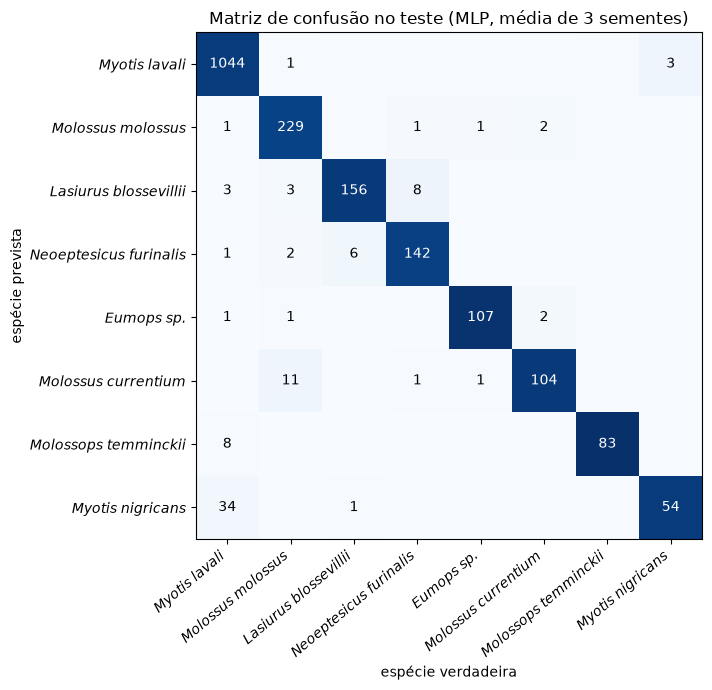

In [15]:
m = np.mean(matrizes, axis=0)
frac = m / m.sum(axis=0, keepdims=True)
nomes = [e.replace("_", " ").replace(" sp", " sp.") for e in ESPECIES]
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if m[i, j] >= 0.5:
            ax.text(j, i, f"{m[i, j]:.0f}", ha="center", va="center", fontsize=10,
                    color="white" if frac[i, j] > 0.5 else "black")
ax.set_xticks(range(N_CLASSES), nomes, rotation=40, ha="right", style="italic")
ax.set_yticks(range(N_CLASSES), nomes, style="italic")
ax.set_xlabel("espécie verdadeira")
ax.set_ylabel("espécie prevista")
ax.set_title("Matriz de confusão no teste (MLP, média de 3 sementes)")
fig.tight_layout()
plt.show()

## Conclusões

- A MLP chega a **acurácia balanceada de 0,959 no teste** (0,966 na validação),
  contra 0,938 do modelo linear com a mesma função custo e 0,697 da regra de FME da
  chave de identificação. A camada oculta reduz o erro em cerca de um terço.
- Todas as espécies são reconhecidas com sensibilidade acima de 0,92. O ponto fraco
  é a **precisão de *Myotis nigricans*** (≈0,61): gravações de *M. lavali*, do mesmo
  gênero e com faixas de frequência vizinhas, são chamadas de *M. nigricans*. É o
  custo do peso por classe, escolhido para não perder a espécie rara.
- Os erros restantes se concentram em pares próximos: *Molossus molossus* ×
  *M. currentium* e *Neoeptesicus furinalis* × *Lasiurus blossevillii*.

**Limitações.** O rótulo é a identificação acústica feita por especialistas (sem
captura), então a métrica mede concordância com eles. As medidas foram extraídas
manualmente do sonograma: a rede não parte do áudio. O modelo conhece só estas 8
espécies, de uma região e de um tipo de gravador. As checagens feitas nos
notebooks de trabalho (rótulos embaralhados, validação cruzada por local) estão
descritas no artigo.